In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import torch
import torch.nn as nn


from sklearn.model_selection import train_test_split

# Linear regression from scratch:

In [2]:
# create a simple straight line data
# y = a * X + b

a = 0.7
b = 0.3 
X = torch.arange(0,1, 0.02)
print(X.shape)

y = a * X + b
print(y.shape)

torch.Size([50])
torch.Size([50])


In [3]:
# split the data into training and testing

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= 42)


len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [4]:
# a function to visualize data

def plot_predictions( train_data = X_train,
                    train_labels = y_train,
                    test_data = X_test,
                    test_labels = y_test,
                    predictions= None):
    
    
    plt.figure(figsize=(12,6))
    plt.scatter(train_data, train_labels, label="Training data", c='b', s=20)
    plt.scatter(test_data, test_labels, label= "Testing data", c='g', s=20)
    
    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")
    plt.legend()
    plt.show()
    
    

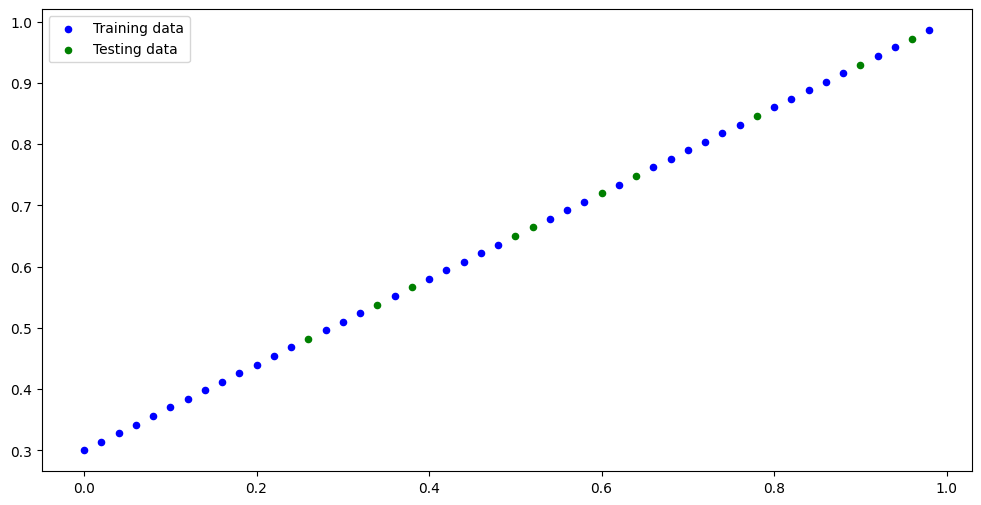

In [5]:
plot_predictions()

In [6]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        
        # on initialise weight et bias avec une valeur aléatoire
        self.weights = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad= True))
        self.bias = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad= True))
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weights * x + self.bias  # Le fonction d'une droite de régression

In [7]:
torch.manual_seed(42) # pour avoir meme résultat à chaque éxecution

model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [8]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [9]:
loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params= model_0.parameters(), lr= 0.01)

In [10]:
# TRAIN AND TEST LOOP 
torch.manual_seed(42)
epochs = 100

train_loss_values = []
test_loss_values = []
epoch_count = []


for epoch in range(epochs):
    # Training
    model_0.train()
    
    # 1- forward pass
    y_pred = model_0(X_train) # pytorch appele automatiquement notre méthode forward
    # 2 calculate loss
    loss = loss_fn(y_pred, y_train)
    # 3 zero grad 
    optimizer.zero_grad()
    # 4 loss backward
    loss.backward()
    # 5 progress the optimizer
    optimizer.step()
    
    
    
    
    
    
    # Testing
    model_0.eval()
    with torch.inference_mode():
        # 1 forward pass
        test_pred = model_0(X_test)
        # 2 loss
        test_loss = loss_fn(test_pred, y_test)
        
        
        # Print out what's happening
        if epoch % 10 == 0:
                epoch_count.append(epoch)
                train_loss_values.append(loss.detach().numpy())
                test_loss_values.append(test_loss.detach().numpy())
                print(f"Epoch: {epoch} | MAE Train Loss: {loss:.7f} | MAE Test Loss: {test_loss:.7f} ")
        

Epoch: 0 | MAE Train Loss: 0.3403112 | MAE Test Loss: 0.3720795 
Epoch: 10 | MAE Train Loss: 0.2186421 | MAE Test Loss: 0.2447080 
Epoch: 20 | MAE Train Loss: 0.1037553 | MAE Test Loss: 0.1229367 
Epoch: 30 | MAE Train Loss: 0.0639980 | MAE Test Loss: 0.0607301 
Epoch: 40 | MAE Train Loss: 0.0516110 | MAE Test Loss: 0.0413299 
Epoch: 50 | MAE Train Loss: 0.0454050 | MAE Test Loss: 0.0339885 
Epoch: 60 | MAE Train Loss: 0.0398040 | MAE Test Loss: 0.0295801 
Epoch: 70 | MAE Train Loss: 0.0342030 | MAE Test Loss: 0.0251716 
Epoch: 80 | MAE Train Loss: 0.0286021 | MAE Test Loss: 0.0207632 
Epoch: 90 | MAE Train Loss: 0.0230011 | MAE Test Loss: 0.0163548 


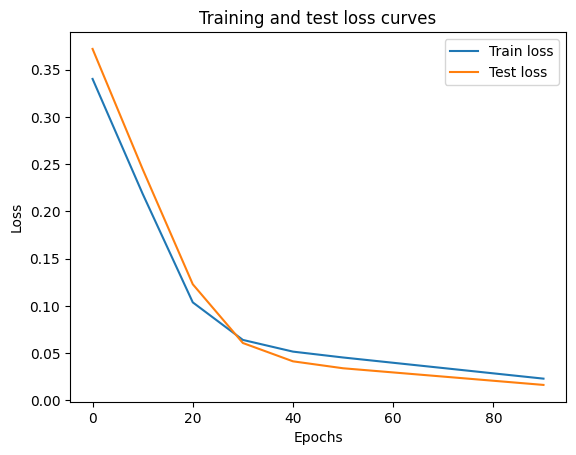

In [11]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

In [12]:
print("The model learned the following values :")
print(model_0.state_dict())
print("\nAnd the original values are:")
print(f"weights: {a}, bias: {b}")

The model learned the following values :
OrderedDict([('weights', tensor([0.6344])), ('bias', tensor([0.3333]))])

And the original values are:
weights: 0.7, bias: 0.3


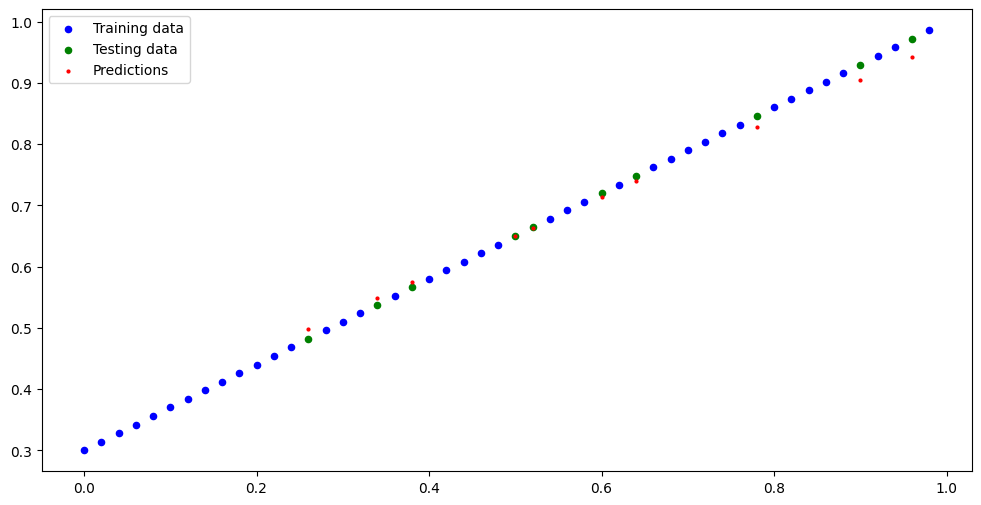

In [13]:
model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)


plot_predictions(predictions= y_preds)

# Régression polynomiale y = a*x + b*x^2 + c*x^3 + d

Ce que tu apprends :

gérer plusieurs poids (nn.Parameter pour chaque puissance de x)

forward plus complexe (combinaison linéaire des puissances de x)

boucle de train identique à celle de la linéaire

Challenge : choisir le bon degré de polynôme et comprendre l’impact sur la loss

In [161]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
import torch
from torch import nn 



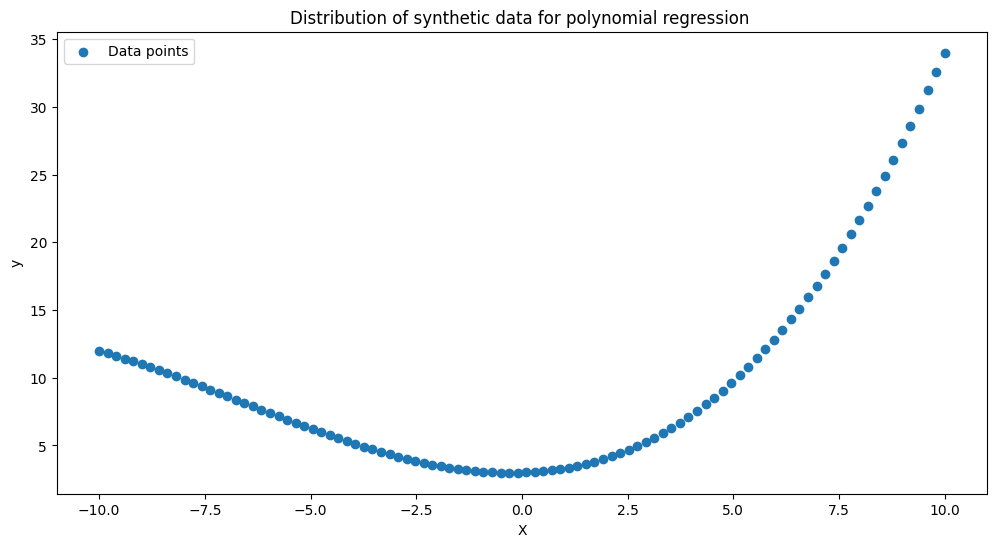

In [173]:
# 1)- Generate synthetic data

np.random.seed(42)

a = 0.1
b = 0.2
c = 0.01
d = 3

X = torch.from_numpy(np.linspace(-10, 10, 100))

y = (a*X) + (b* X**2) + (c * X**3) + d

plt.figure(figsize=(12,6))
plt.scatter(X, y , label= 'Data points')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.title('Distribution of synthetic data for polynomial regression ')
plt.show()



In [174]:
print(len(X), len(y))

100 100


In [175]:
# 2)- Splitting the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

80 80
20 20


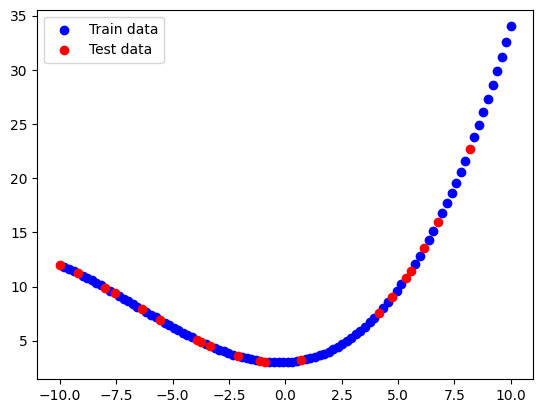

In [176]:
def plot_data_predicion(train_label = X_train,
                        test_label = X_test,
                        train_target = y_train,
                        test_target = y_test,
                        predictions = None):
    
    plt.scatter(train_label, train_target, label= "Train data", c= 'b')
    plt.scatter(test_label, test_target, label = "Test data", c= 'r')
    
    if predictions is not None:
        plt.scatter(test_label, predictions, label= "Predictions", c= 'g' )
    
    plt.legend()
    plt.show()
    
plot_data_predicion()

In [177]:
# 3)- Polynomial regression

class PolynomialRegressionModel(nn.Module):
    def __init__(self):
        super().__init__() 
        
        # first we need to initialize a b c d randomly
        
        self.a = nn.Parameter(torch.randn(1, dtype= torch.float))
        self.b = nn.Parameter(torch.randn(1, dtype= torch.float))
        self.c = nn.Parameter(torch.randn(1, dtype= torch.float))
        self.d = nn.Parameter(torch.randn(1, dtype= torch.float))
        
    
    # The forward function == polynomial regression  y = a*X + b*X^2 + c*X^3 + d
    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return ( (self.a * X) + (self.b * X**2) + (self.c * X**3) + (self.d) ) 
    

    

In [178]:
# 4)- Model Initialiation
torch.manual_seed(42)
polyno_regr_model = PolynomialRegressionModel()
polyno_regr_model.state_dict()

OrderedDict([('a', tensor([0.3367])),
             ('b', tensor([0.1288])),
             ('c', tensor([0.2345])),
             ('d', tensor([0.2303]))])

In [179]:
# 5)- loss function and optimizer

loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params= polyno_regr_model.parameters(), lr= 0.01)


In [180]:
# 6)- Train and test loop

torch.manual_seed(42)

epochs= 10000

epoch_count = []
train_loss_values = []
test_loss_values = []


for epoch in range(epochs):
    # TRAIN
    polyno_regr_model.train()
    
    y_preds = polyno_regr_model(X_train)
    loss = loss_fn(y_train, y_preds)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    
    # TEST
    polyno_regr_model.eval()
    with torch.inference_mode():
        test_preds = polyno_regr_model(X_test)
        test_loss = loss_fn(y_test, test_preds)
        
        
    # Optionnel
    if (epoch %10 ==0):
        epoch_count.append(epoch)
        train_loss_values.append(loss.detach().numpy())
        test_loss_values.append(test_loss.detach().numpy())
        #print(f'Epoch :  {epoch} | Train loss : {loss} | Test loss : {test_loss} ')

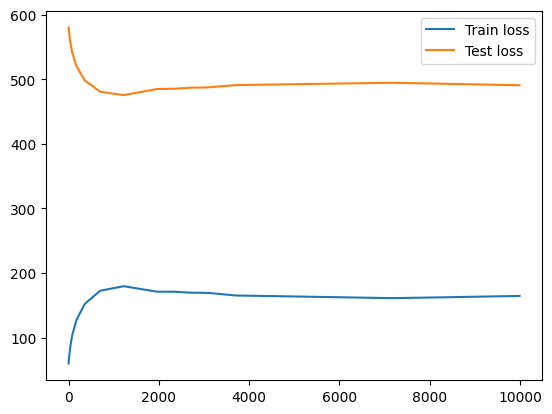

In [181]:
plt.plot(epoch_count, train_loss_values, label='Train loss')
plt.plot(epoch_count, test_loss_values, label='Test loss')
plt.legend()
plt.show()

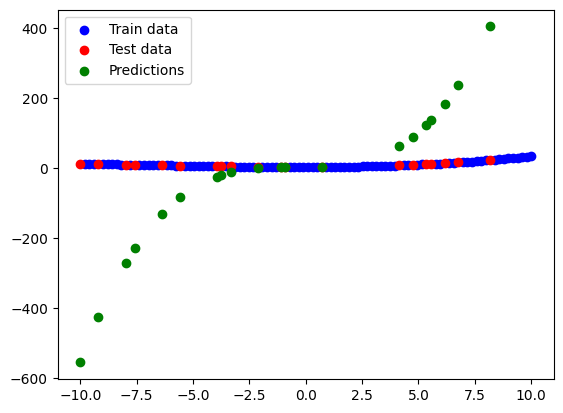

In [182]:
# 7)- make predictions
polyno_regr_model.eval()
with torch.inference_mode():
    predictions = polyno_regr_model(X_test)
    
    
plot_data_predicion(predictions= predictions)

In [183]:
polyno_regr_model._parameters

OrderedDict([('a',
              Parameter containing:
              tensor([0.2082], requires_grad=True)),
             ('b',
              Parameter containing:
              tensor([0.7809], requires_grad=True)),
             ('c',
              Parameter containing:
              tensor([0.6343], requires_grad=True)),
             ('d',
              Parameter containing:
              tensor([2.9870], requires_grad=True))])

 The model still needs some improvements !!!!!!!!!!!

# Régression multivariée : y = a*x + b*z + c


Ce que tu apprends :

gérer weights comme un tenseur vectoriel

multiplication matricielle dans forward (x @ weights + bias)

même boucle train/test mais plus proche des vrais datasets

# Logistique regression : σ(w*x +b)

Classification binaire simple (logistic regression)


Ce que tu apprends :

fonction d’activation dans forward

fonction de perte adaptée (nn.BCELoss)

gradients avec une fonction non linéaire

Challenge : comprendre comment la non-linéarité change le calcul du gradient